<a href="https://colab.research.google.com/github/vragarwal/FDS-Results/blob/main/vradhi%20exp%207%20fds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [6]:
from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print(df.head())

Saving V_S_DATA SET_CLIMATE.csv to V_S_DATA SET_CLIMATE (2).csv
       country  longitude        timezone      last_updated  \
0  Afghanistan      69.18      Asia/Kabul  16-05-2024 13:15   
1      Albania      19.82   Europe/Tirane  16-05-2024 10:45   
2      Algeria       3.05  Africa/Algiers  16-05-2024 09:45   
3      Andorra       1.52  Europe/Andorra  16-05-2024 10:45   
4       Angola      13.23   Africa/Luanda  16-05-2024 09:45   

   temperature_celsius condition_text  wind_kph  wind_degree wind_direction  \
0                 26.6  Partly Cloudy      13.3          338            NNW   
1                 19.0  Partly cloudy      11.2          320             NW   
2                 23.0          Sunny      15.1          280              W   
3                  6.3  Light drizzle      11.9          215             SW   
4                 26.0  Partly cloudy      13.0          150            SSE   

   precip_mm  humidity  visibility_km  gust_mph  air_quality_Ozone  \
0        0.0

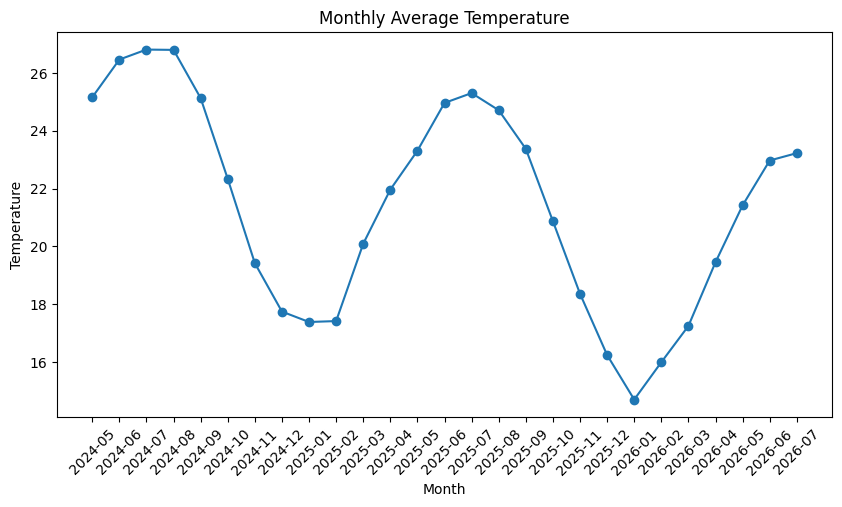

In [7]:
df['last_updated'] = pd.to_datetime(df['last_updated'], errors='coerce', dayfirst=True)

df['Month'] = df['last_updated'].dt.to_period('M')

monthly_temp = df.groupby('Month')['temperature_celsius'].mean()

plt.figure(figsize=(10,5))
plt.plot(monthly_temp.index.astype(str), monthly_temp.values, marker='o')
plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.show()

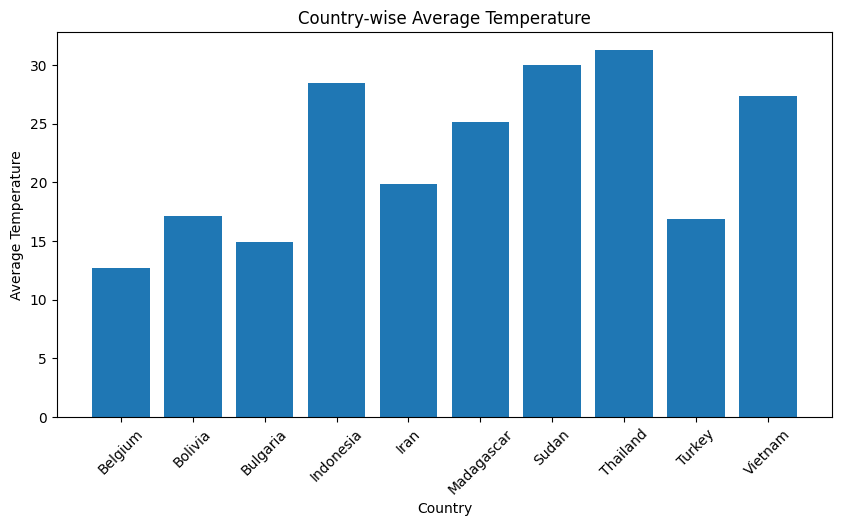

In [8]:
top_countries = df['country'].value_counts().head(10).index

country_temp = df[df['country'].isin(top_countries)].groupby('country')['temperature_celsius'].mean()

plt.figure(figsize=(10,5))
plt.bar(country_temp.index, country_temp.values)
plt.title("Country-wise Average Temperature")
plt.xlabel("Country")
plt.ylabel("Average Temperature")
plt.xticks(rotation=45)
plt.show()

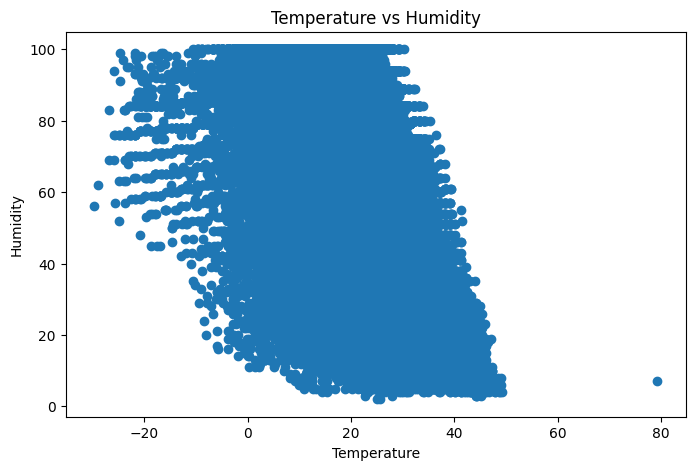

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(df['temperature_celsius'], df['humidity'])
plt.title("Temperature vs Humidity")
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.show()

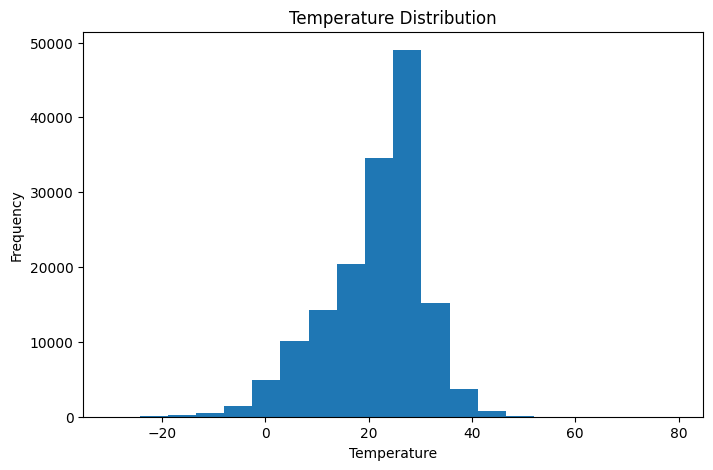

In [10]:
plt.figure(figsize=(8,5))
plt.hist(df['temperature_celsius'].dropna(), bins=20)
plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.show()

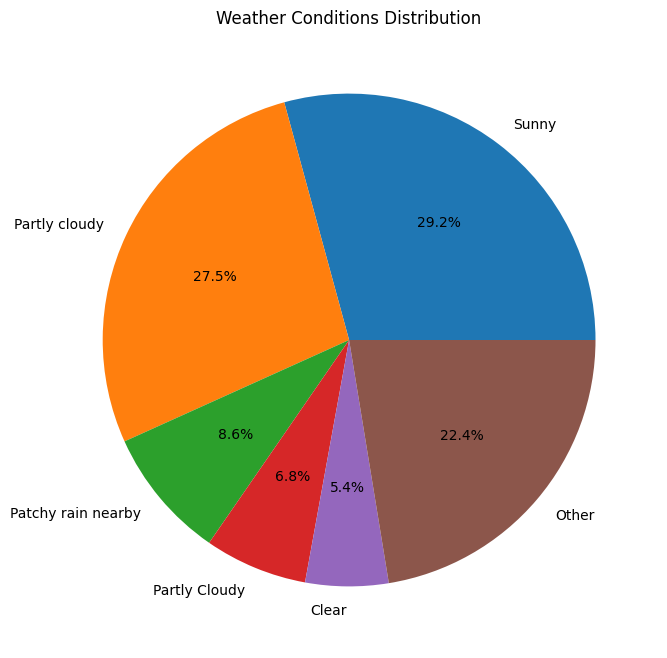

In [11]:
conditions = df['condition_text'].value_counts().head(5)

other = df['condition_text'].value_counts().iloc[5:].sum()
conditions['Other'] = other

plt.figure(figsize=(8,8))
plt.pie(conditions, labels=conditions.index, autopct='%1.1f%%')
plt.title("Weather Conditions Distribution")
plt.show()